<a href="https://colab.research.google.com/github/DataAnalytics808/DASC-522-demo-repository/blob/main/demos/Homework_2_template_v7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> &nbsp; | &nbsp; [https://colab.research.google.com/github/DataAnalytics808/DASC-522-demo-repository/blob/main/demos/Homework_2_template_v7.ipynb](https://colab.research.google.com/github/DataAnalytics808/DASC-522-demo-repository/blob/main/demos/Homework_2_template_v7.ipynb)

This link is provided in case you are viewing this on GitHub, so that it is easy to open directly in Colab.

When opened in Colab, click "Copy to Drive" in the menu above to copy this file to your Colab account.


## Homework #2

## Part 1: Data Understanding / Modeling

A. The following sections of code are broken out into logical chunks, using multiple "text" and "code" sections, beginning with the preamble below:

In [125]:
# import a library or two (or lots)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.max_rows", 500)
pd.set_option("display.max_columns", 500)
pd.set_option("display.width", 1000)
import scipy.stats as stats
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf


B. Load the datafile with df = pd.read_csv("https://raw.githubusercontent.com/DataAnalytics808/DASC-522-demo-repository/main/data/LRS_Pre_Assessment_trimmed_rank.csv"). Drop the “flight” column and one-hot-encode the “rank” & “gender” columns with df_ohe = pd.get_dummies(df, drop_first=True, dtype='int').

*   drop_first is needed so the columns are linearly independent - this prevents multi-colinearity in your models.
*   get_dummies() has been recently updated within pandas to give boolean values by default - this can cause an error later in your sm.Logit() models.  Specifying a datatype of integer with dtype='int' prevents an error.


In [126]:
# Load dataset from GitHub repository (with local fallback)
url = "https://raw.githubusercontent.com/DataAnalytics808/DASC-522-demo-repository/main/data/LRS_Pre_Assessment_trimmed_rank.csv"
try:
    df = pd.read_csv(url)
except Exception:
    df = pd.read_csv("LRS_Pre_Assessment_trimmed_rank.csv")

df.drop(columns=['Flight'], inplace=True)
df_ohe = pd.get_dummies(df, drop_first=True, dtype='int')

df.head()


,Rank,Age,Gender,ORS_total,PTSD_score,Sleep_score,survey_Burnout,survey_FitSat,BMI,BodyFatPerc,MusclePerc,APFT_1_is_pass
0,JrEnlisted,40,M,9.8,5,8,2,3,27.9,0.3000,0.328,1
1,JrEnlisted,22,M,5.0,22,10,4,2,33.0,0.3680,0.308,0
2,JrEnlisted,20,M,9.6,1,3,1,3,24.8,0.0273,0.356,0
3,JrEnlisted,21,F,5.0,12,13,5,3,24.5,0.4160,0.221,1
4,JrEnlisted,27,M,8.3,0,6,1,5,23.7,0.2120,0.385,1


C. Create a Data Understanding table using .describe() and include 3 Data Understanding visualizations such as a scatterplot, histogram, pairplot or correlation matrix.

In [127]:
df_ohe.describe()

,Age,ORS_total,PTSD_score,Sleep_score,survey_Burnout,survey_FitSat,BMI,BodyFatPerc,MusclePerc,APFT_1_is_pass,Rank_SrEnlisted,Rank_officer,Gender_M
count,157.000000,157.000000,157.000000,157.000000,157.000000,157.000000,157.000000,157.000000,157.000000,157.000000,157.000000,157.000000,157.000000
mean,27.942675,7.620382,9.312102,7.305732,2.140127,3.331210,27.110191,0.294873,0.327968,0.707006,0.509554,0.038217,0.757962
std,6.164666,1.955621,11.795182,3.939710,0.812235,0.803746,4.093791,0.086974,0.060547,0.456592,0.501508,0.192332,0.429688
min,19.000000,0.200000,0.000000,0.000000,1.000000,1.000000,18.400000,0.014700,0.036500,0.000000,0.000000,0.000000,0.000000
25%,23.000000,6.700000,1.000000,4.000000,2.000000,3.000000,24.400000,0.248000,0.289000,0.000000,0.000000,0.000000,1.000000
50%,26.000000,8.000000,5.000000,7.000000,2.000000,3.000000,27.100000,0.296000,0.334000,1.000000,1.000000,0.000000,1.000000
75%,33.000000,9.000000,12.000000,10.000000,2.000000,4.000000,29.700000,0.346000,0.366000,1.000000,1.000000,0.000000,1.000000
max,45.000000,10.000000,68.000000,22.000000,5.000000,5.000000,38.300000,0.495000,0.473000,1.000000,1.000000,1.000000,1.000000


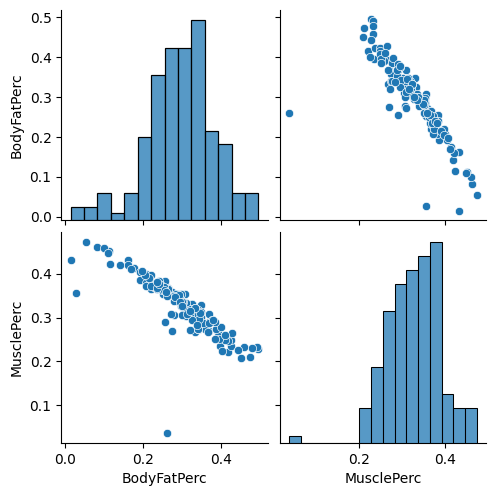

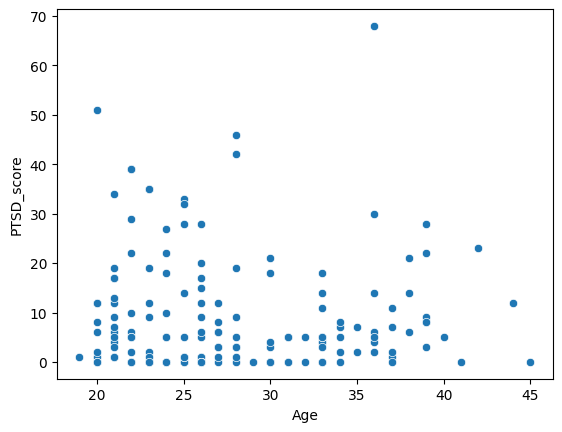

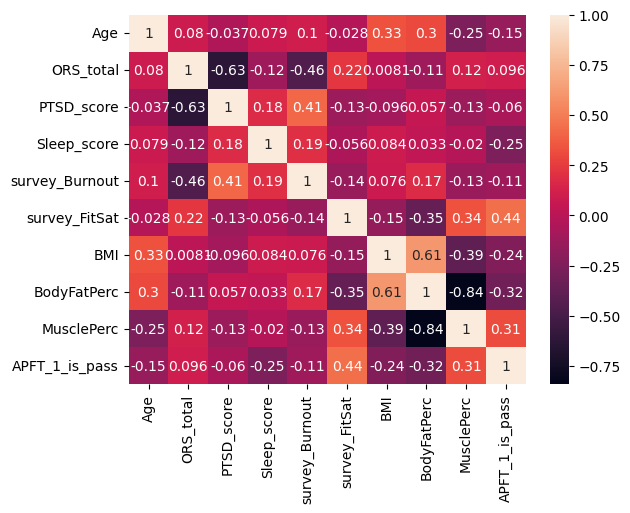

In [128]:
df_ohe.describe()

sns.pairplot(df_ohe,vars=['BodyFatPerc','MusclePerc'])
plt.show()

sns.scatterplot(data=df_ohe,x='Age',y='PTSD_score')
plt.show()

matrix = df.corr(numeric_only=True)
sns.heatmap(matrix, annot=True)
plt.show()

The distribution of these independent variables are non-normal, so we will transform them after the test/train split.

D. Split df_ohe into 70% train & 30% test

In [129]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df_ohe, test_size=0.3, random_state=10)

E. Build Model 1: Train a statsmodels sm.Logit algorithm on the train dataset

In [130]:
y_train1 = train_df['APFT_1_is_pass']
X_train1 = train_df.drop(columns=['APFT_1_is_pass'])

model_1 = sm.Logit(y_train1, X_train1).fit()

print(model_1.summary())

         Current function value: 0.368633
         Iterations: 35
                           Logit Regression Results                           
Dep. Variable:         APFT_1_is_pass   No. Observations:                  109
Model:                          Logit   Df Residuals:                       97
Method:                           MLE   Df Model:                           11
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.3637
Time:                        15:07:48   Log-Likelihood:                -40.181
converged:                      False   LL-Null:                       -63.143
Covariance Type:            nonrobust   LLR p-value:                 3.334e-06
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Age                -0.0653      0.059     -1.108      0.268      -0.181       0.050
ORS_total          -0.0086      0.183     -0.047  

/usr/local/lib/python3.13/dist-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


F. Create a copy of the dataframe using df_xform = df_ohe.copy(deep=True)

In [131]:
xform_df = df_ohe.copy(deep=True)

G. While using the week 3 “DASC 522 guide to feature standardization & transformation” for assistance, on df_xform:
*   plot the distribution of the 3 features mentioned below, before transformation
*   perform a box-cox transform on the Age and ORS_total features
*   perform a yeo-johnson transform on the PTSD_score feature
*   plot the distribution of the 3 features mentioned above, after transformation

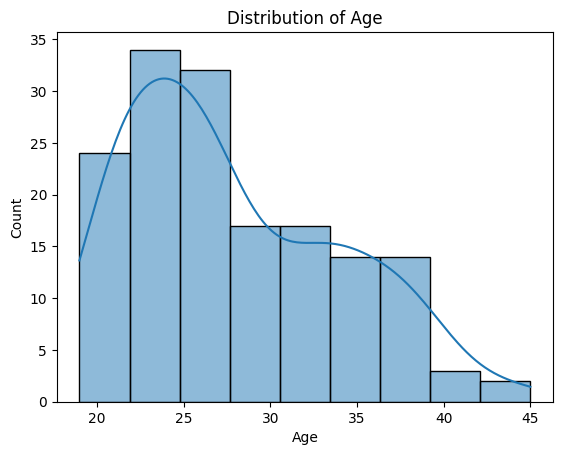

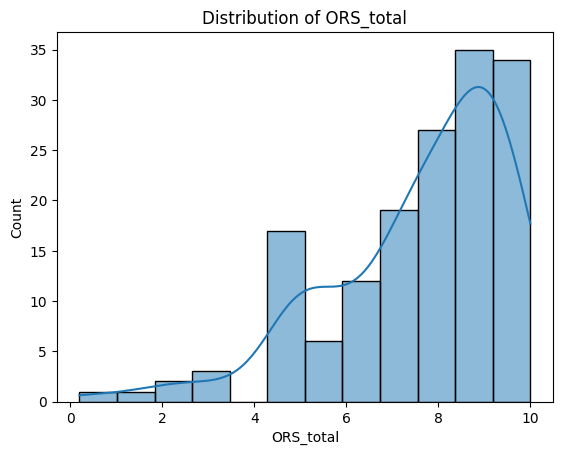

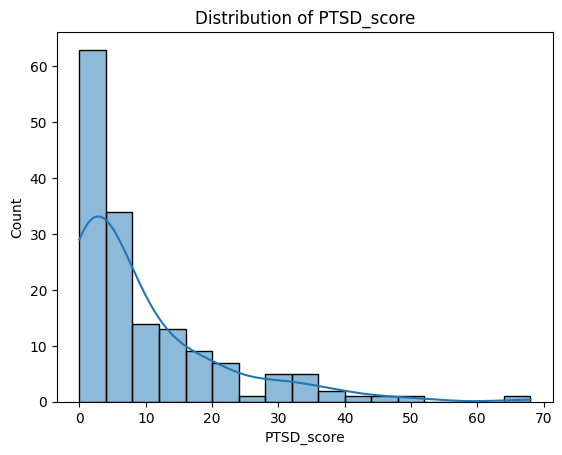

In [132]:
sns.histplot(xform_df['Age'],kde=True)
title = 'Distribution of Age'
plt.title(title)
plt.show()

sns.histplot(xform_df['ORS_total'],kde=True)
plt.title('Distribution of ORS_total')
plt.show()

sns.histplot(xform_df['PTSD_score'],kde=True)
plt.title('Distribution of PTSD_score')
plt.show()

In [133]:
xform_df['Age'],flambda1 = stats.boxcox(xform_df['Age'])
xform_df['ORS_total'],flambda2 = stats.boxcox(xform_df['ORS_total'])
xform_df['PTSD_score'],flambda3 = stats.yeojohnson(xform_df['PTSD_score'])

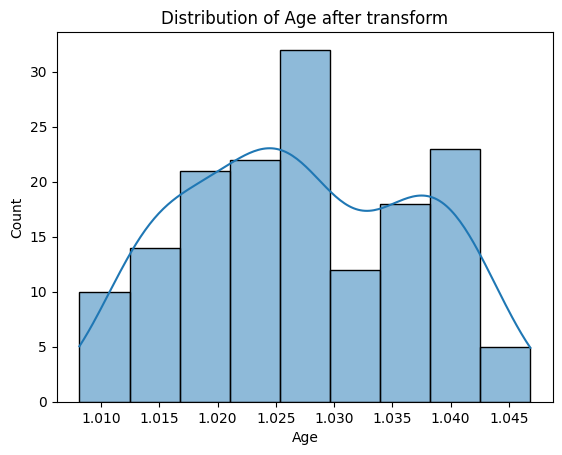

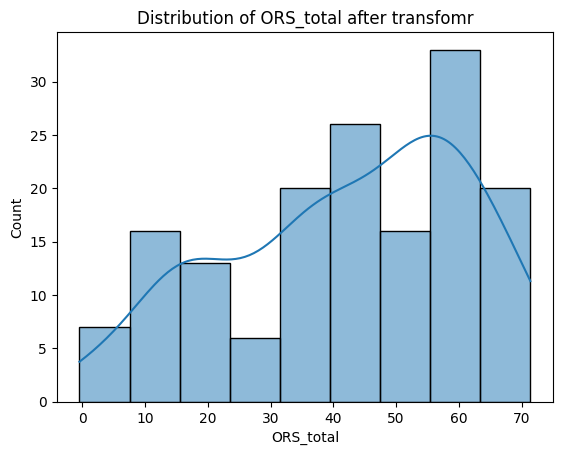

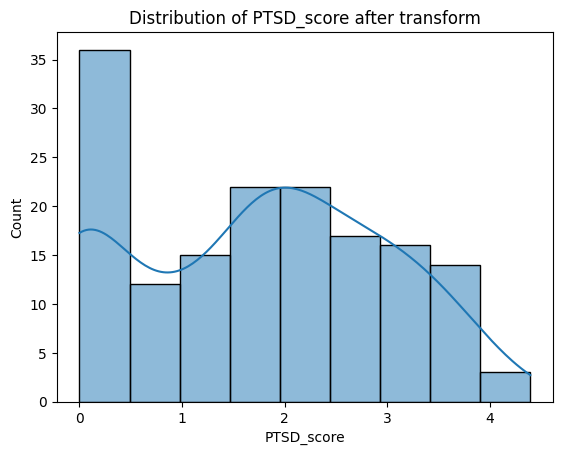

In [134]:
sns.histplot(xform_df['Age'],kde=True)
title = 'Distribution of Age after transform'
plt.title(title)
plt.show()

sns.histplot(xform_df['ORS_total'],kde=True)
plt.title('Distribution of ORS_total after transfomr')
plt.show()

sns.histplot(xform_df['PTSD_score'],kde=True)
plt.title('Distribution of PTSD_score after transform')
plt.show()

H. On df_xform, standardize all features using StandardScaler() except for the label APFT_1_is_pass. Transforming/standardizing the label is generally not recommended because it reduces the explainability of your model.

In [135]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
featuresToScale = xform_df.columns.drop('APFT_1_is_pass')
xform_df[featuresToScale] = scaler.fit_transform(xform_df[featuresToScale])

I. Display df_xform’s statistics using df_xform.describe(), and verify


*   the transformed features have mean very close to 0 & standard deviation very close to 1
*   APFT_1_is_pass has not been transformed - it should have min = 0, and max=1. sm.Logit needs the label to be either 0 or 1
*   The transformed features **do** have a mean very close to zero, the standard deviation **is** very close to 1, and the label **hasn't** been transformed



In [136]:
xform_df.describe()

,Age,ORS_total,PTSD_score,Sleep_score,survey_Burnout,survey_FitSat,BMI,BodyFatPerc,MusclePerc,APFT_1_is_pass,Rank_SrEnlisted,Rank_officer,Gender_M
count,1.570000e+02,1.570000e+02,1.570000e+02,1.570000e+02,1.570000e+02,1.570000e+02,1.570000e+02,1.570000e+02,1.570000e+02,157.000000,157.000000,1.570000e+02,1.570000e+02
mean,-2.047902e-15,3.889316e-17,-2.262875e-17,5.657187e-17,1.697156e-17,8.485781e-17,4.525750e-17,-3.337741e-16,3.518063e-17,0.707006,0.000000,3.394312e-17,-1.131437e-16
std,1.003200e+00,1.003200e+00,1.003200e+00,1.003200e+00,1.003200e+00,1.003200e+00,1.003200e+00,1.003200e+00,1.003200e+00,0.456592,1.003200,1.003200e+00,1.003200e+00
min,-1.961616e+00,-2.251246e+00,-1.393380e+00,-1.860317e+00,-1.408183e+00,-2.909715e+00,-2.134467e+00,-3.231640e+00,-4.829343e+00,0.000000,-1.019294,-1.993366e-01,-1.769627e+00
25%,-7.902414e-01,-6.866289e-01,-8.311567e-01,-8.417653e-01,-1.730728e-01,-4.134021e-01,-6.641432e-01,-5.406503e-01,-6.456551e-01,0.000000,-1.019294,-1.993366e-01,5.650909e-01
50%,-1.407890e-01,5.974137e-02,7.426127e-02,-7.785112e-02,-1.730728e-01,-4.134021e-01,-2.497366e-03,1.300382e-02,9.995259e-02,1.000000,0.981071,-1.993366e-01,5.650909e-01
75%,9.290923e-01,7.430340e-01,7.221690e-01,6.860630e-01,-1.730728e-01,8.347542e-01,6.346431e-01,5.897268e-01,6.301625e-01,1.000000,0.981071,-1.993366e-01,5.650909e-01
max,2.009895e+00,1.523751e+00,2.151606e+00,3.741720e+00,3.532259e+00,2.082910e+00,2.742108e+00,2.308361e+00,2.403052e+00,1.000000,0.981071,5.016639e+00,5.650909e-01


J. Model #2: split df_xform into train/test datasets, and train a statsmodels sm.Logit() algorithm on the train dataset.

In [137]:
train_df, test_df = train_test_split(xform_df, test_size=0.3, random_state=33)

y_train2 = train_df['APFT_1_is_pass']
X_train2 = train_df.drop(columns=['APFT_1_is_pass'])

model_2 = sm.Logit(y_train2, X_train2).fit()

print(model_2.summary())

Optimization terminated successfully.
         Current function value: 0.413744
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:         APFT_1_is_pass   No. Observations:                  109
Model:                          Logit   Df Residuals:                       97
Method:                           MLE   Df Model:                           11
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.3409
Time:                        15:07:51   Log-Likelihood:                -45.098
converged:                       True   LL-Null:                       -68.419
Covariance Type:            nonrobust   LLR p-value:                 2.490e-06
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Age                 0.1977      0.411      0.481      0.631      -0.608       1.004
ORS_total     

K. Model #3: using the training dataset from df_xform, perform feature selection using p-value selection.   
*   Use the P>|z| values from the model summary, not the LLR p-value.    
*   Remove features one at a time until all remaining features have p < 0.05, which is 95% confidence they are statistically significant.


In [138]:
X_train3 = train_df.drop(columns=['APFT_1_is_pass','Rank_officer'])
model_3 = sm.Logit(y_train2, X_train3).fit()

print(model_3.summary())

Optimization terminated successfully.
         Current function value: 0.414094
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:         APFT_1_is_pass   No. Observations:                  109
Model:                          Logit   Df Residuals:                       98
Method:                           MLE   Df Model:                           10
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.3403
Time:                        15:07:51   Log-Likelihood:                -45.136
converged:                       True   LL-Null:                       -68.419
Covariance Type:            nonrobust   LLR p-value:                 1.133e-06
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Age                 0.2335      0.389      0.600      0.548      -0.529       0.996
ORS_total     

In [139]:
X_train3 = train_df.drop(columns=['APFT_1_is_pass','Rank_officer','Age'])
model_3 = sm.Logit(y_train2, X_train3).fit()

print(model_3.summary())

Optimization terminated successfully.
         Current function value: 0.415754
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:         APFT_1_is_pass   No. Observations:                  109
Model:                          Logit   Df Residuals:                       99
Method:                           MLE   Df Model:                            9
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.3377
Time:                        15:07:51   Log-Likelihood:                -45.317
converged:                       True   LL-Null:                       -68.419
Covariance Type:            nonrobust   LLR p-value:                 5.520e-07
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
ORS_total           0.3934      0.341      1.154      0.249      -0.275       1.062
PTSD_score    

In [140]:
X_train3 = train_df.drop(columns=['APFT_1_is_pass','Rank_officer','Age',
                                 'Rank_SrEnlisted'])
model_3 = sm.Logit(y_train2, X_train3).fit()

print(model_3.summary())

Optimization terminated successfully.
         Current function value: 0.417224
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:         APFT_1_is_pass   No. Observations:                  109
Model:                          Logit   Df Residuals:                      100
Method:                           MLE   Df Model:                            8
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.3353
Time:                        15:07:51   Log-Likelihood:                -45.477
converged:                       True   LL-Null:                       -68.419
Covariance Type:            nonrobust   LLR p-value:                 2.502e-07
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
ORS_total          0.3614      0.335      1.080      0.280      -0.294       1.017
PTSD_score       

In [141]:
X_train3 = train_df.drop(columns=['APFT_1_is_pass','Rank_officer','Age',
                                 'Rank_SrEnlisted','Gender_M'])
model_3 = sm.Logit(y_train2, X_train3).fit()

print(model_3.summary())

Optimization terminated successfully.
         Current function value: 0.419493
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:         APFT_1_is_pass   No. Observations:                  109
Model:                          Logit   Df Residuals:                      101
Method:                           MLE   Df Model:                            7
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.3317
Time:                        15:07:51   Log-Likelihood:                -45.725
converged:                       True   LL-Null:                       -68.419
Covariance Type:            nonrobust   LLR p-value:                 1.150e-07
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
ORS_total          0.3067      0.322      0.952      0.341      -0.324       0.938
PTSD_score       

In [142]:
X_train3 = train_df.drop(columns=['APFT_1_is_pass','Rank_officer','Age',
                                 'Rank_SrEnlisted','Gender_M','survey_Burnout'])
model_3 = sm.Logit(y_train2, X_train3).fit()

print(model_3.summary())

Optimization terminated successfully.
         Current function value: 0.423611
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:         APFT_1_is_pass   No. Observations:                  109
Model:                          Logit   Df Residuals:                      102
Method:                           MLE   Df Model:                            6
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.3251
Time:                        15:07:51   Log-Likelihood:                -46.174
converged:                       True   LL-Null:                       -68.419
Covariance Type:            nonrobust   LLR p-value:                 5.908e-08
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
ORS_total         0.3955      0.305      1.298      0.194      -0.202       0.993
PTSD_score        0.

In [143]:
X_train3 = train_df.drop(columns=['APFT_1_is_pass','Rank_officer','Age',
                                 'Rank_SrEnlisted','Gender_M','survey_Burnout',
                                 'PTSD_score'])
model_3 = sm.Logit(y_train2, X_train3).fit()

print(model_3.summary())

Optimization terminated successfully.
         Current function value: 0.430680
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:         APFT_1_is_pass   No. Observations:                  109
Model:                          Logit   Df Residuals:                      103
Method:                           MLE   Df Model:                            5
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.3139
Time:                        15:07:51   Log-Likelihood:                -46.944
converged:                       True   LL-Null:                       -68.419
Covariance Type:            nonrobust   LLR p-value:                 3.783e-08
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
ORS_total         0.2234      0.268      0.834      0.404      -0.302       0.749
Sleep_score      -0.

In [144]:
X_train3 = train_df.drop(columns=['APFT_1_is_pass','Rank_officer','Age',
                                 'Rank_SrEnlisted','Gender_M','survey_Burnout',
                                 'PTSD_score','ORS_total'])
model_3 = sm.Logit(y_train2, X_train3).fit()

print(model_3.summary())

Optimization terminated successfully.
         Current function value: 0.433887
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:         APFT_1_is_pass   No. Observations:                  109
Model:                          Logit   Df Residuals:                      104
Method:                           MLE   Df Model:                            4
Date:                Fri, 30 Oct 2026   Pseudo R-squ.:                  0.3088
Time:                        15:07:51   Log-Likelihood:                -47.294
converged:                       True   LL-Null:                       -68.419
Covariance Type:            nonrobust   LLR p-value:                 1.480e-08
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Sleep_score      -0.6633      0.274     -2.420      0.016      -1.201      -0.126
survey_FitSat     1.

## Part 2: Metrics & Overfitting


A. Calculate the accuracy (on the test dataset) for Model 1/2/3, and use that to determine the “best” variation. The test dataset is critical to detecting overfitting on the model created from the train dataset, so use the model created from the train dataset. It will make me sad if you make a new model from the test dataset 🥺.

In [145]:
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.metrics import accuracy_score

y_pred_prob = model_1.predict(test_df.drop(columns=['APFT_1_is_pass']))
y_pred = np.where(y_pred_prob > 0.5, 1, 0)
y_test = test_df['APFT_1_is_pass']

print(accuracy_score(y_test, y_pred))

0.3541666666666667


In [146]:
y_pred_prob = model_2.predict(test_df.drop(columns=['APFT_1_is_pass']))
y_pred = np.where(y_pred_prob > 0.5, 1, 0)
y_test = test_df['APFT_1_is_pass']

print(accuracy_score(y_test, y_pred))

0.5833333333333334


In [147]:
y_pred_prob = model_3.predict(test_df.drop(columns=['APFT_1_is_pass','Rank_officer','Age',
                                 'Rank_SrEnlisted','Gender_M','survey_Burnout',
                                 'PTSD_score','ORS_total']))
y_pred = np.where(y_pred_prob > 0.5, 1, 0)
y_test = test_df['APFT_1_is_pass']

print(accuracy_score(y_test, y_pred))

0.6458333333333334


B. While the course example uses the LogisticRegression() algorithm, use sm.Logit() to calculate AUC & ROC below. This will require some investigation as the prediction methods differ.   
i.	For the “best” model, using the train dataset, create a ROC curve plot and calculate the accuracy, odds ratio, AUC, classification report and confusion matrix.  
ii.	For the “best” model, using the test dataset, create a ROC curve plot and calculate the accuracy, AUC, classification report and confusion matrix.

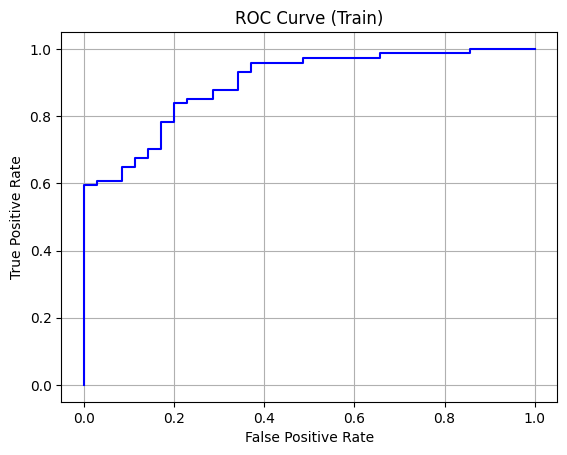

In [148]:
# part i

y_pred_prob_train = model_3.predict(X_train3)
y_pred = np.where(y_pred_prob > 0.5, 1, 0)
y_test = test_df['APFT_1_is_pass']

f, t, thresholds = metrics.roc_curve(y_train2, y_pred_prob_train)
plt.plot(f, t, color='blue', label='ROC')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Train)')
plt.grid(True)

In [149]:
# Convert training probabilities to binary predictions (0 or 1) using a 0.5 threshold
y_pred_train = np.where(y_pred_prob_train > 0.5, 1, 0)

print("Accuracy:", accuracy_score(y_train2, y_pred_train))
print("AUC Score:", roc_auc_score(y_train2, y_pred_prob_train))
print("\nClassification Report:\n", classification_report(y_train2, y_pred_train))
print("Confusion Matrix:\n", confusion_matrix(y_train2, y_pred_train))

# Calculate Odds Ratios for Model 3
odds_ratios = np.exp(model_3.params)
print("\nOdds Ratios for Model 3:")
print(odds_ratios)

Accuracy: 0.7706422018348624
AUC Score: 0.8980694980694981

Classification Report:
               precision    recall  f1-score   support

           0       0.60      0.83      0.70        35
           1       0.90      0.74      0.81        74

    accuracy                           0.77       109
   macro avg       0.75      0.79      0.76       109
weighted avg       0.81      0.77      0.78       109

Confusion Matrix:
 [[29  6]
 [19 55]]

Odds Ratios for Model 3:
Sleep_score       0.515134
survey_FitSat     5.196001
BMI               0.205731
BodyFatPerc      27.334249
MusclePerc       26.362054
dtype: float64


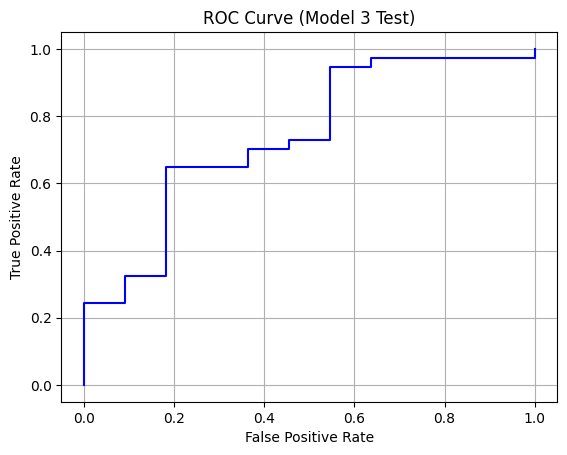

In [152]:
# part ii - Plot ROC Curve for Model 3 on Test Set
y_pred_prob_test = model_3.predict(test_df.drop(columns=['APFT_1_is_pass','Rank_officer','Age',
                                 'Rank_SrEnlisted','Gender_M','survey_Burnout',
                                 'PTSD_score','ORS_total']))
y_pred_test = np.where(y_pred_prob_test > 0.5, 1, 0)

f, t, thresholds = metrics.roc_curve(y_test, y_pred_prob_test)
plt.plot(f, t, color='blue', label='ROC')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Model 3 Test)')
plt.grid(True)
plt.show()

In [ ]:

print("Accuracy (Test):", accuracy_score(y_test, y_pred_test))
print("AUC Score (Test):", roc_auc_score(y_test, y_pred_prob_test))
print("\nClassification Report (Test):\n", classification_report(y_test, y_pred_test))
print("Confusion Matrix (Test):\n", confusion_matrix(y_test, y_pred_test))


odds_ratios = np.exp(model_3.params)
print("\nOdds Ratios for Model 3:")
print(odds_ratios)


Accuracy (Test): 0.6458333333333334
AUC Score (Test): 0.7395577395577395

Classification Report (Test):
               precision    recall  f1-score   support

           0       0.38      0.82      0.51        11
           1       0.92      0.59      0.72        37

    accuracy                           0.65        48
   macro avg       0.65      0.71      0.62        48
weighted avg       0.79      0.65      0.67        48

Confusion Matrix (Test):
 [[ 9  2]
 [15 22]]

Odds Ratios for Model 3:
Sleep_score       0.515134
survey_FitSat     5.196001
BMI               0.205731
BodyFatPerc      27.334249
MusclePerc       26.362054
dtype: float64


##Part 3: Discussion
 write in a formal writing style based on the Appendix B guidance, with the exception that references and citations are not required

A. Discuss these Business/Mission Understanding topics after reviewing the “Binary Classification metric summary” file from the week 2 Canvas page:   
1.	Mention what the majority class is (either passing or failing the test), the % of datapoints in the majority class and whether or not the dataset is balanced.    
2.	Discuss the potential penalties associated with a False Negative and False Positive. Mention if the penalties are equal or unequal. This is subjective, and there isn't a wrong answer.
3.	Discuss the metrics (accuracy/f1/etc) that would be most appropriate for this problem based on the balance & penalties

1.  The majority class in the dataset is 1.0. This corresponds to passing the the APFT. Out of 157 total individuals in the original dataset, 111 passed. This indicates the majority class represents 70.70% of the dataset, which is 67.89% in the generated training split. Because the original dataset did not correspond to an even 50/50 split, We can concluded the dataset was **imbalanced**

2.   A false positive would indicate that an individual would pass the fitness test, but in fact could not actually pass in reality. This could readiness issues in the case of critical duties that require such fitness.

  A false negative would indicate that a fit individual would be marked as unable to pass the test. This could lead to manpower issues, as individuals who could be serving in critical roles would not be able to serve in those roles.

3.   Since the datset is imbalanced, accuracy would not be the best choice of metric for this problem. A more optimal choice would be to maximize precision for the passing class, as a false positive carries an greater assesed penalty than a false negative.

B.	Please discuss these topics:       
1.	Discuss the most important 2-3 input variables, based on their z or p test scores.     
2.	Discuss tradeoffs in performance vs complexity, i.e. model metrics vs. number of features  
3. Based on the train & test dataset performance, mention if the best model has overfit the data   

1.   Based on outputs of model 3, the most important predictors are BMI and Fitness satisfaction. BMI had a highly negative z score, while fitness satisfaction had a highly positive one. This indicates highly neagative and positive correlations with these predictors.
2.   Model 3 incorporates the least number of predictors, while generating the best performace overall. While this model included data transformations and stepwise reduction in predictors, It performs more accurately than the other 2 models, based on stastical outputs generated in this homework.
3.   There is evidence of overfitting in model 3. The AUC did drop in model 3 between the training and test datasetindicating that overfitting could be an issue, which is an common in smaller datasets such as this one.



